In [5]:
# -- uncomment to get interactive plots
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pmoired

# -- in case you want to limit the number of cores for the multiprocessing functions
# -- will take all CPUs otherwise! 
pmoired.MAX_THREADS = 6 
print('will use', pmoired.MAX_THREADS, 'CPUs for multiprocessing')

will use 6 CPUs for multiprocessing


-- Please aknowledge the use of PMOIRED -----------
https://github.com/amerand/PMOIRED#using-and-quoting-pmoired
--------------------------------------------------- 
loadOI: loading MIRC_L2.2014Jul29.GL_586A.MIRCX_IDL.JDM.SPLIT.oifits
  > insname: "H_PRISM" targname: "GL_586A" pipeline: "" calibrated: unknown
  > MJD: (50,) [56867.1781..56867.1902] ~2014-07-29T04:23:58.707
  > E2-S2-W2 | WL: (8,) [ 1.485 .. 1.726 ] um (R~48 P~47) {'T3': 1, 'VIS': 3, 'VIS2': 3} | TELL: False 


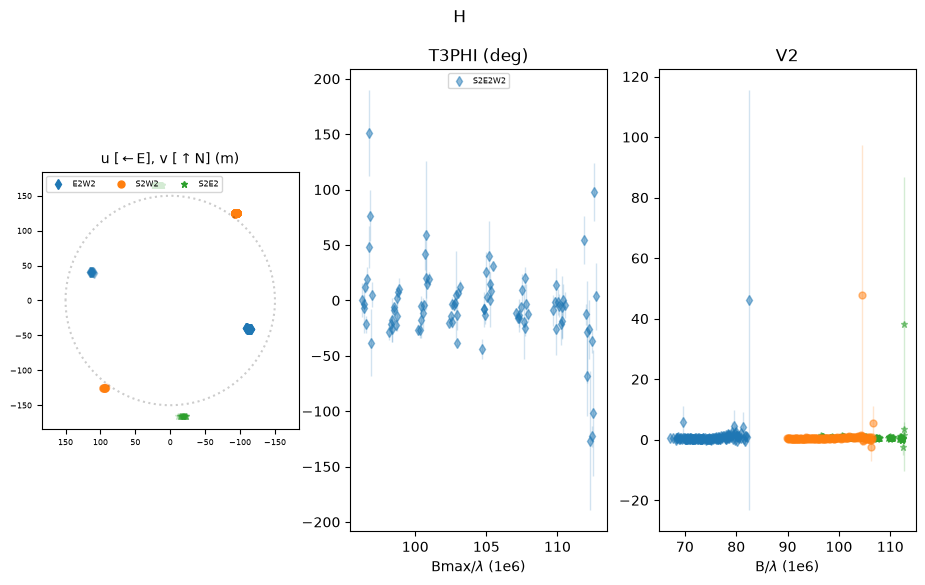

In [6]:
oi = pmoired.OI('MIRC_L2.2014Jul29.GL_586A.MIRCX_IDL.JDM.SPLIT.oifits') #binning=3)
oi.show(obs=['V2', 'T3PHI'])

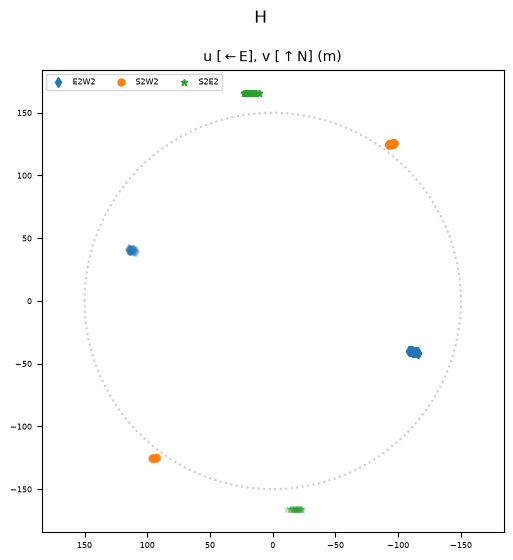

In [7]:
oi.show(obs=['']) # Show u, v only
# oi.show(obs=['V2']) 

In [8]:
plx = 51.1421 # mas from Gaia
R1 = 0.92 # From Strassmeier et al. 2013
R2 = 0.59 # From Strassmeier et al. 2013
R_Solar = 6.957e+8 # solar radii in meters
d_pc = 3.086e16 # pc in meters

data = oi.data[0]
print(data.keys())
print('\n')
print(f'Instrument: {data['insname']}')
print(f'Telescopes: {data['telescopes']}')
print(f'Baselines: {data['baselines']}')
print(f'Triangles: {data['triangles']}')
print('Mean MJD:', np.mean(data['MJD']))
print('Median MJD:', np.median(data['MJD']))
print('Duration of Observation (min)', 24*60*(np.max(data['MJD']) - np.min(data['MJD'])))

dict_keys(['insname', 'filename', 'targname', 'pipeline', 'LST', 'header', 'calibrated', 'WL', 'dWL', 'OI_VIS2', 'OI_VIS', 'OI_T3', 'units', 'telescopes', 'baselines', 'triangles', 'TELLURICS', 'configurations per MJD', 'MJD', 'recipes'])


Instrument: H_PRISM
Telescopes: ['E2', 'S2', 'W2']
Baselines: ['E2W2', 'S2E2', 'S2W2']
Triangles: ['S2E2W2']
Mean MJD: 56867.183318367184
Median MJD: 56867.18300116784
Duration of Observation (min) 17.50555007136427


In [9]:
wl = data['WL']
d_wl = data['dWL']
print(f'Lambda (um)', wl)
print('Delta Lambda (um)', d_wl)
print('Spectral Resolution R', wl/d_wl)


wl_min = np.min(wl)
wl_max = np.max(wl)
wl_mean = np.mean(wl)
R_mean = np.mean(wl/d_wl)
print('Mean Wavelength (um):',wl_mean)
print('Mean R:', R_mean)


Lambda (um) [1.48529011 1.51428094 1.55092243 1.58704938 1.62266167 1.65775941
 1.69234249 1.72585044]
Delta Lambda (um) [0.0251656  0.03281616 0.03638422 0.03586962 0.03535501 0.03484041
 0.03404551 0.03297043]
Spectral Resolution R [59.02064068 46.14436661 42.62623618 44.24494751 45.89622362 47.58151077
 49.70823879 52.34539724]
Mean Wavelength (um): 1.6045196105096693
Mean R: 48.44594517537905


In [10]:
# Get min and max baseline lengths for each baseline

data = oi.data[0]

baseline_lengths = {}                
for b in data['baselines']:
    v = data['OI_VIS2'][b]
    baseline_lengths[b] = np.hypot(v['u'], v['v'])   
    #print(b, np.round(baseline_lengths[b], 2))


max_baselines = []
min_baselines = []
print("Baseline, Min (m), Max (m)")
for b in data['baselines']:
    print(b, baseline_lengths[b].min(), baseline_lengths[b].max())
    max_baselines.append(baseline_lengths[b].max())
    min_baselines.append(baseline_lengths[b].min())
    # usually go to 1/4 * lamda/longest baseline


# MAXIMUM BASELINE LENGTHS (in meters) FOR EACH BASELINE:
# BASELINE: W1S2; 247.98848075397257 m
# WAVELENGTH: 1.587e-06 m

Bmax = np.max(max_baselines) # meters
Bmin = np.min(min_baselines) # meters
wavelength = wl_mean / 1e6 # meters
fineness_factor = 1/4
max_resolution = fineness_factor * (wavelength / Bmax) * 206265e3 # in mas, 0.329997742239 mas
print('Max Baseline', Bmax, 'm')
print('Min Baseline', Bmin, 'm')
print('Fringe Spacing', (wavelength / Bmax) * 206265e3, 'mas')
print(f'Maximum Resolution for Search', max_resolution, "mas")

Baseline, Min (m), Max (m)
E2W2 115.92747584593675 122.56303931444002
S2E2 165.92469620981237 167.35943575798754
S2W2 155.0804795051514 158.26078091918703
Max Baseline 167.35943575798754 m
Min Baseline 115.92747584593675 m
Fringe Spacing 1.9775176461538797 mas
Maximum Resolution for Search 0.4943794115384699 mas


In [11]:
# Angular Diameter Calculation

theta_ud1 = 206265e3 * ((2 * R1 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
theta_ud2 = 206265e3 * ((2 * R2 * R_Solar) / ((1/(plx*1e-3)) * d_pc))
print('UD1:',theta_ud1)
print('UD2:',theta_ud2)

UD1: 0.43757046743171013
UD2: 0.2806158432442489


setupFit> 0/H_PRISM: setting 'wl kernel':1.0 according to WL definition
22660 grid points not within constraints
Tue Nov  3 22:53:52 2026: running 80381 fits on 10 processes
Tue Nov  3 23:08:56 2026: [████████████████████████████████████████████████████████████]80381/80381   0s   leftt

Tue Nov  3 23:08:56 2026: it took 904.1s, 0.01s per fit on average [5334.3 fit/minute]
fits to be taken into account: 80299 / 80381
  82 have uncertainties larger than the grid's step[s]
Tue Nov  3 23:08:58 2026: making list of unique minima...
Tue Nov  3 23:12:20 2026: [████████████████████████████████████████████████████████████]80299/80299   0s   left

unique minima: 106 / 80299 [~757.5 first guesses / minima]
  few unique minima -> grid too fine / Nfits too large?
Tue Nov  3 23:12:20 2026: linking unique minima to first guess(es)
Tue Nov  3 23:12:20 2026: done
------------
best fit: chi2= 3.1241911158366644
{'B,x': -4.609, # +/- 0.058
'B,y': 0.588, # +/- 0.013
'A,f': 1.0,
'A,ud':0.43757046743171013,

/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
/Users/ethanchen/ASTRO2/ASTRO399/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


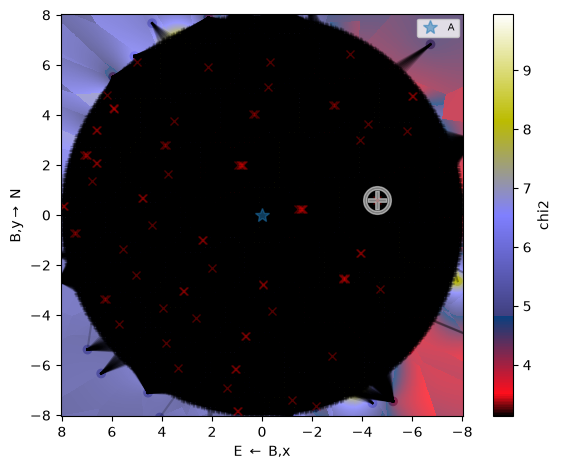

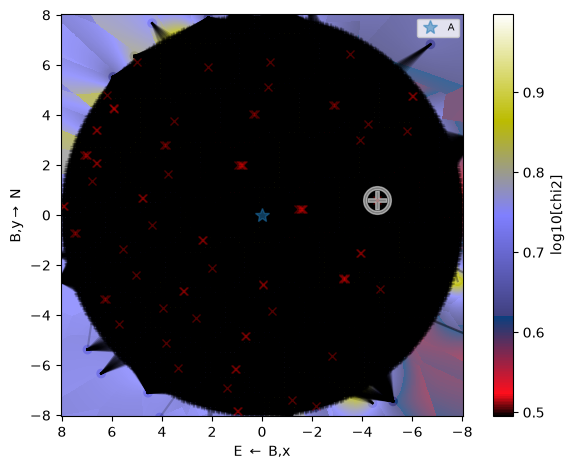

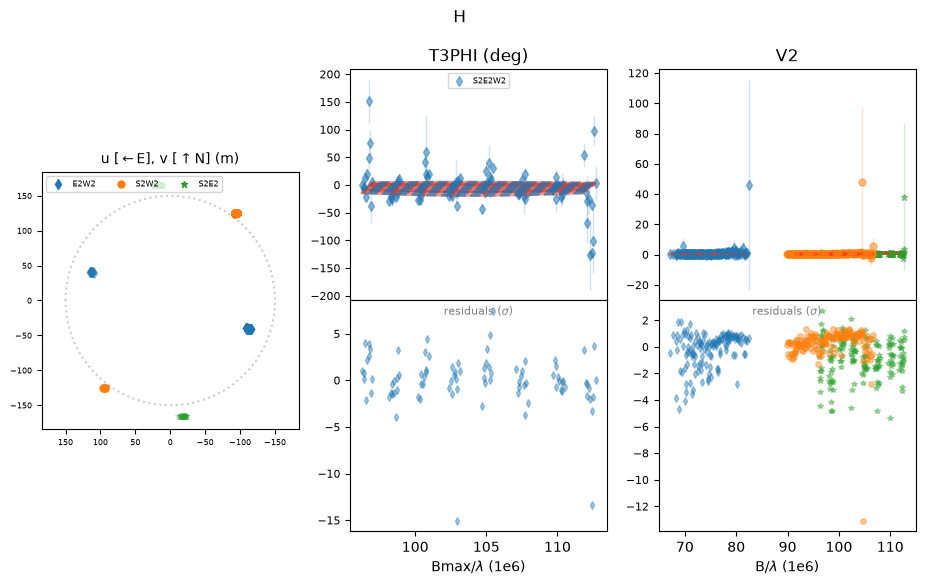

In [12]:
# Define model
# A at the origin, B offset (x East, y North, in mas)

maxsep1 = 8.0
step1 = 0.05

param = {
    'A,f': 1.0,
    'A,ud': theta_ud1,      
    'A,x': 0.0, 'A,y': 0.0,
    'B,f': 0.2362529748,         # flux relative to A, initial guess at 2014-08-02 fit
    'B,ud': theta_ud2,      
    'B,x': 0.0, 'B,y': 0.0,
}

# Flux of B must be lower than A component
prior = [('B,f', '<', 1)]

# Constraints on B's position
# - Separation must be less than the maximum separation
constrain = [( 'np.sqrt(B,x**2+B,y**2)', '<', maxsep1)]


# parameters that will be fixed and not fitted
fixed = ['A,f', 'A,ud', 'A,x', 'A,y', 'B,ud', 'B,f'] # Fix B,f for bad fits


oi.setupFit({'obs': ['V2', 'T3PHI'], 'min relative error': {'V2': 0.01}})


# Grid search over B's position
expl = {'grid': {'B,x': (-maxsep1, maxsep1, step1), 'B,y': (-maxsep1, maxsep1, step1)}}
oi.gridFit(expl, model=param, doNotFit=fixed, constrain=constrain, prior=prior)

# -- show the grid result
oi.showGrid()

# -- show the log grid result
oi.showGrid(interpolate=True, logV=1)

# -- show the data and the best fit model
oi.show()

In [14]:
# list the distinct minima it found in the unzoomed, best first
rows1 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows1.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows1.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows1[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

-----------------------------------------
  chi2r    sep(mas)   PA(deg)   f_B/f_A
3.1241911158366644  4.6459851303526545  277.26914017760424  0.2362529748
3.2519042185199916  7.10743506410544  260.532698812209  0.2362529748
3.257890061122266  1.5570818125936425  278.9040518163785  0.2362529748
3.2736591129474633  3.219843628027433  316.38103981614603  0.2362529748
3.284518426415129  4.215014090498642  249.00369223436857  0.2362529748
3.3820817134836676  5.9568841341031185  296.74005500308056  0.2362529748
3.40609517920911  7.770789595194739  276.91980218561037  0.2362529748
3.499502005048102  7.206272790112811  242.94850415034216  0.2362529748


In [15]:
# The best fit position of component B, not zoomed in
x1 = oi.bestfit['best']['B,x']
y1 = oi.bestfit['best']['B,y']
pa1 = np.degrees(np.arctan2(x1, y1)) % 360
print(f'{x1}, {y1} mas, PA = {pa1} deg')

-4.608644123236214, 0.5878581264372204 mas, PA = 277.26914017760424 deg


In [ ]:
# Refine the fit around the best fit point (x1, y1)

maxsep2 = 10
step2 = max_resolution        # half-width and step, in mas

expl = {'grid': {'B,x': (x1-maxsep2, x1+maxsep2, step2),
                 'B,y': (y1-maxsep2, y1+maxsep2, step2)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [ ]:
# list the distinct minima it found in the zoomed, best first
rows2 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows2.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows2.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows2[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

In [ ]:
# The best fit position of component B, zoomed in
x2 = oi.bestfit['best']['B,x']
y2 = oi.bestfit['best']['B,y']
pa2 = np.degrees(np.arctan2(x2, y2)) % 360
print(f'{x2}, {y2} mas, PA = {pa2} deg')

In [ ]:
# Refine the fit around the best fit point

x3 = x2
y3 = y2
maxsep3 = 1
step3 = 0.02        # half-width and step, in mas

expl = {'grid': {'B,x': (x2-maxsep3, x2+maxsep3, step3),
                 'B,y': (y2-maxsep3, y2+maxsep3, step3)}}

oi.gridFit(expl, model=oi.bestfit['best'], doNotFit=fixed, prior=prior)   # no constrain
oi.showGrid()
oi.showGrid(interpolate=True, logV=1)
oi.show()

In [ ]:
# list the distinct minima it found in the zoomed, best first
rows3 = []
for r in oi.grid:
    if r['bad']:
        continue
    b = r['best']
    rows3.append((r['chi2'], b['B,x'], b['B,y'], b['B,f']))
rows3.sort()

print('-----------------------------------------')
print('  chi2r    sep(mas)   PA(deg)   f_B/f_A')
for chi2, x, y, f in rows3[:8]:
    print(f'{chi2}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}  {f}')

In [ ]:
# The best fit position of component B, zoomed in for a second time
x3 = oi.bestfit['best']['B,x']
y3 = oi.bestfit['best']['B,y']
pa3 = np.degrees(np.arctan2(x3, y3)) % 360
print(f'{x3}, {y3} mas, PA = {pa3} deg')

In [ ]:
# Refine Fit using the zoomed best fit, Bx_zoom, By_zoom
oi.doFit(oi.bestfit['best'], doNotFit=fixed)
oi.showFit()

In [ ]:
# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

In [ ]:
# Uncertainties

oi.bootstrapFit(Nfits=500)
oi.showBootstrap()

In [ ]:
# BEST FIT PARAMETERS AND UNCERTAINTIES

# Separation and position angle
b = oi.bestfit['best']
x, y = b['B,x'], b['B,y']
sep = np.hypot(x, y)
pa = np.degrees(np.arctan2(x, y)) % 360
print(f"sep = {sep} mas, PA = {pa} deg, f_B/f_A = {b['B,f']}")
print(x, y)

In [ ]:
# Summary of all the Grid Fits

print(f"Grid Size: {2*maxsep1} x {2*maxsep1} mas; Step = {step1} mas")
print(f"    Bx: {x1} mas; By: {y1} mas; PA = {pa1} deg")
print(f"Grid Size: {2*maxsep2} x {2*maxsep2} mas; Step = {step2} mas")
print(f"    Bx: {x2} mas; By: {y2} mas; PA = {pa2} deg")
print(f"Grid Size: {2*maxsep3} x {2*maxsep3} mas; Step = {step3} mas")
print(f"    Bx: {x3} mas; By: {y3} mas; PA = {pa3} deg")

In [16]:
# More readable grids without the movement of the fits plotted
# The dofit model (not using grid fit and keeping Bx, By fixed) searches in an area centered around the best fit of the last gridfit model (x3, y3)


start = dict(oi.bestfit['best']) # includes x3, y3, B,f and the fixed params
start['B,x'] = x1
start['B,y'] = y1

x1_2, y1_2 = x1, y1

maxsep1_2 = 8
step1_2 = 0.1       # half-width and step, in mas

xs = np.arange(x1_2-maxsep1_2, x1_2+maxsep1_2+step1_2/2, step1_2)
ys = np.arange(y1_2-maxsep1_2, y1_2+maxsep1_2+step1_2/2, step1_2)
frozen = fixed + ['B,x', 'B,y'] # B,f is still fitted at each point

chi2 = np.zeros((len(ys), len(xs)))

progress = 0

for j, y in enumerate(ys):
    for i, x in enumerate(xs):
        p = dict(start); p['B,x'], p['B,y'] = x, y
        oi.doFit(p, doNotFit=frozen, prior=prior, verbose=0)
        chi2[j, i] = oi.bestfit['chi2']

    progress += len(xs)
    print(f'{progress}/{len(xs)*len(ys)}')

oi.doFit(start, doNotFit=fixed, verbose=0)   # restore oi.bestfit

161/25921
322/25921
483/25921
644/25921
805/25921
966/25921
1127/25921
1288/25921
1449/25921
1610/25921
1771/25921
1932/25921
2093/25921
2254/25921
2415/25921
2576/25921
2737/25921
2898/25921
3059/25921
3220/25921
3381/25921
3542/25921
3703/25921
3864/25921
4025/25921
4186/25921
4347/25921
4508/25921
4669/25921
4830/25921
4991/25921
5152/25921
5313/25921
5474/25921
5635/25921
5796/25921
5957/25921
6118/25921
6279/25921
6440/25921
6601/25921
6762/25921
6923/25921
7084/25921
7245/25921
7406/25921
7567/25921
7728/25921
7889/25921
8050/25921
8211/25921
8372/25921
8533/25921
8694/25921
8855/25921
9016/25921
9177/25921
9338/25921
9499/25921
9660/25921
9821/25921
9982/25921
10143/25921
10304/25921
10465/25921
10626/25921
10787/25921
10948/25921
11109/25921
11270/25921
11431/25921
11592/25921
11753/25921
11914/25921
12075/25921
12236/25921
12397/25921
12558/25921
12719/25921
12880/25921
13041/25921
13202/25921
13363/25921
13524/25921
13685/25921
13846/25921
14007/25921
14168/25921
14329/25921


Text(0, 0.5, 'B,y (mas, N →)')

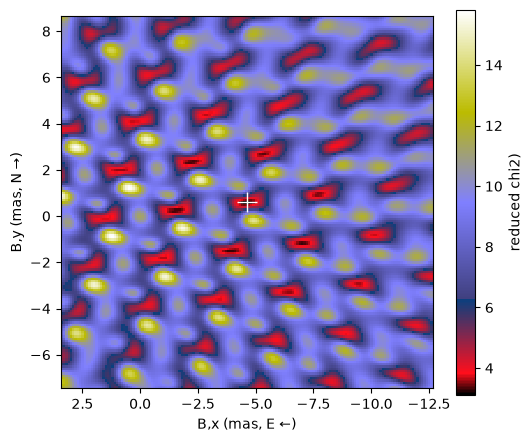

In [17]:

plt.figure(figsize=(6, 5))

plt.pcolormesh(xs, ys, chi2, cmap='gist_stern')

plt.plot(x1, y1, marker='+', color='w', ms=14, mew = 1)


plt.colorbar(label='reduced chi2)')
plt.gca().invert_xaxis(); plt.gca().set_aspect('equal')
plt.xlabel('B,x (mas, E ←)'); plt.ylabel('B,y (mas, N →)')



In [ ]:
# Print the n grid points with the lowest chi2, with their B,x and B,y

n = 500                                           # how many to print

order = np.argsort(chi2, axis=None)              # flat indices, lowest chi2 first
order = order[np.isfinite(chi2.flat[order])]     # drop NaN (uncomputed) points

print(f'Top {min(n, len(order))} lowest chi2 grid points')
print('  rank    chi2r       B,x        B,y     sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]}  {x}  {y}  {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

print('  rank    chi2r      sep(mas)   PA(deg)')
for rank, k in enumerate(order[:n], start=1):
    j, i = np.unravel_index(k, chi2.shape)       # row (y), column (x)
    x, y = xs[i], ys[j]
    print(f'{rank}  {chi2[j, i]} {np.hypot(x, y)}  {np.degrees(np.arctan2(x, y)) % 360}')

Top 50 lowest chi2 grid points
  rank    chi2r       B,x        B,y     sep(mas)   PA(deg)
1  3.1128510391911597  -4.6086441232362425  0.587858126437192  4.645985130352679  277.26914017760384
2  3.151877839426648  -4.708644123236242  0.587858126437192  4.745198273634669  277.11636123707217
3  3.152733231113027  -4.508644123236243  0.587858126437192  4.546806462431731  277.4285853722599
4  3.2675958409673496  -4.808644123236242  0.587858126437192  4.844443774134724  276.96984108914
5  3.274127214988578  -3.908644123236245  -1.5121418735628005  4.190951196076047  248.8499808155686
6  3.275048788803916  -4.408644123236243  0.587858126437192  4.447664576175199  277.5951402187325
7  3.2863848019607604  -4.008644123236245  -1.5121418735628005  4.284367018888379  249.33250716621808
8  3.306871301800952  -7.008644123236234  -1.2121418735628016  7.112691499553326  260.18778498747906
9  3.308483592331762  -3.8086441232362453  -1.5121418735628005  4.0978461541697735  248.3454908518155
10  3.31219

In [ ]:
# To scale, based off calculated uds
disp = dict(oi.bestfit['best'])
oi.showModel(disp, imFov=1.2*maxsep1, imPix=0.1, imPow=0.5, showSED=False)

In [ ]:
# Not to scale
disp = dict(oi.bestfit['best'])
disp['A,ud'] = 5      # display size only, not measured
disp['B,ud'] = 4
oi.showModel(disp, imFov=0.5*maxsep1, imPix=0.6, imPow=1, showSED=False)